In [1]:
import numpy as np
import matplotlib.pyplot as plt
import fastplotlib as fpl
import scipy
from scipy import linalg
import seaborn as sns
from matplotlib import pyplot as plt
import fastplotlib as fpl
import tifffile

%matplotlib inline

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/pygfx/utils/_dirs.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [2]:
path = "/Users/rshang/Work/caiman/mesmerize-core/exp_data/demoMovie.tif"

movie = tifffile.imread(path)[:, ::2, ::2]

# Convert the data type to float32
movie = movie.astype(np.float32)

In [3]:
from skophys.preprocessing import UnVectorizer, Vectorizer

unvec = UnVectorizer(movie.shape[1:])
vectorizer = Vectorizer()
X = vectorizer.fit_transform(movie).T

/opt/anaconda3/envs/mescore/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [22]:
n_pixels = X.shape[1]
n_time_steps = X.shape[0]

# P = np.zeros((n_time_steps,n_pixels-1))
# F = np.zeros((n_time_steps,n_pixels-1))
# for col in range(0,n_pixels-1):
#     P[:,col] = X[:,col]
#     F[:,col] = X[:,col+1]

P = np.zeros((n_time_steps-1,n_pixels))
F = np.zeros((n_time_steps-1,n_pixels))
for row in range(0,n_time_steps-1):
    P[row,:] = X[row,:]
    F[row,:] = X[row+1,:]

print (f"X.shape = {X.shape}")
print (f"P.shape = {P.shape}")
print (f"F.shape = {F.shape}")

X.shape = (2000, 1200)
P.shape = (1999, 1200)
F.shape = (1999, 1200)


In [23]:
def centered_matrix(X):
    # we assume X has a shape (T,N)
    # N = number of features
    # T = number of samples
    
    X_mean = X.mean(axis=1, keepdims=True) # has a shape of T x 1
    print (f"X_mean.shape = {X_mean.shape}")

    return X - X_mean

In [24]:
Pc = centered_matrix(P)
Fc = centered_matrix(F)

X_mean.shape = (1999, 1)
X_mean.shape = (1999, 1)


In [25]:
def eigen_decomposition(M):
    # output eigenvalues and eigenvectors sorted by eigenvalues
    
    eigenvalues, eigenvectors = np.linalg.eig(M)
    eigenvalues = np.real(eigenvalues)
    eigenvectors = np.real(eigenvectors)
    
    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]
    print (f"eigenvectors.shape = {eigenvectors.shape}")

    return eigenvalues, eigenvectors

In [26]:
def covariance_matrix(X):
    # we assume X has a shape (T,N)
    # N = number of features
    # T = number of samples
    
    N = X.shape[1]
    COV = X.T @ X / float(N)
    
    return COV

In [27]:
def whitened_matrix(X):
    # we assume X has a shape (T,N)
    # N = number of features
    # T = number of samples
    
    COV = covariance_matrix(X)
    S, U = eigen_decomposition(COV)

    # Epsilon is added to the eigenvalues to prevent division by zero
    epsilon = 1e-5
    inv_sqrt_S = np.diag(1.0 / np.sqrt(S + epsilon))

    # whitening matrix
    W = U @ inv_sqrt_S @ U.T

    # whitened data
    Xw = X @ W

    return Xw

In [28]:
Pw = whitened_matrix(P)
Fw = whitened_matrix(F)
print (f"P.shape = {P.shape}")
print (f"Pw.shape = {Pw.shape}")

# verify that Pw is whitened data
COV = covariance_matrix(Pw)
print (COV)

eigenvectors.shape = (1200, 1200)
eigenvectors.shape = (1200, 1200)
P.shape = (1999, 1200)
Pw.shape = (1999, 1200)
[[ 1.00000000e+00  7.36132229e-11  1.27399868e-12 ...  1.79384034e-11
  -7.58135036e-13 -3.88087118e-12]
 [ 7.36132229e-11  1.00000000e+00  5.54240165e-11 ... -3.55223806e-11
   2.99700176e-11  6.29902797e-13]
 [ 1.27399868e-12  5.54240165e-11  1.00000000e+00 ... -3.16796663e-12
  -6.41550516e-12  6.32976708e-12]
 ...
 [ 1.79384034e-11 -3.55223806e-11 -3.16796663e-12 ...  9.99999999e-01
   8.89703333e-11  4.18581111e-11]
 [-7.58135036e-13  2.99700176e-11 -6.41550516e-12 ...  8.89703333e-11
   1.00000000e+00  1.10368024e-10]
 [-3.88087118e-12  6.29902797e-13  6.32976708e-12 ...  4.18581111e-11
   1.10368024e-10  1.00000000e+00]]


In [29]:
Z = np.hstack((Pw, Fw))
ZTZ = Z.T @ Z

In [30]:
S, U = eigen_decomposition(ZTZ)

eigenvectors.shape = (2400, 2400)


U.shape = (2400, 2400)


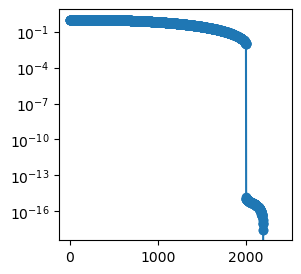

In [31]:
print (f"U.shape = {U.shape}")

fig, ax = plt.subplots(figsize=(3, 3))
ax.plot(S[:] / S.max(),'o-')
ax.set_yscale('log')
# ax.set_xscale('log')
plt.show()

In [32]:
k = 40
Uk = U[:,:k]
Sk = np.diag(np.sqrt(S[:k]))
print (f"Uk.shape = {Uk.shape}")

Uk.shape = (2400, 40)




In [33]:
Y = Sk @ Uk.T
Y1 = Y[:,:n_pixels]
Y2 = Y[:,n_pixels-2:]

image_array = []
for entry in range(0,k):

    snapshot = unvec.transform(Y1[entry,:])
    image_array += [snapshot]

fig, ax = plt.subplots(k, 1, figsize=(6.4, k * 4.8))
for row in range(0,k):
    ax[row].imshow(image_array[row])
plt.show()

In [55]:
from tqdm.notebook import tqdm

eta = 1e-2
error_stop = 1e-4
error_log = np.zeros(20_000)

Y = np.abs(Sk @ Uk.T)

epsilon = 1e-5
epsilon_mtx = np.ones_like(Y@Y.T@Y) * epsilon

beta = 0.01
# beta = 1.0
# beta = 100.

for n_iter in tqdm(range(300)):
    Y_old = Y.copy()

    gamma = Y_old @ ZTZ / (beta * Y_old @ Y_old.T @ Y_old + epsilon_mtx)
    Y = Y_old * (1-eta) + eta * Y_old * gamma

    Y = Y.clip(0)  

    er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta
    error_log[n_iter] = er
    # print (f"er = {er}")

    if er < error_stop:
        break

  0%|          | 0/300 [00:00<?, ?it/s]

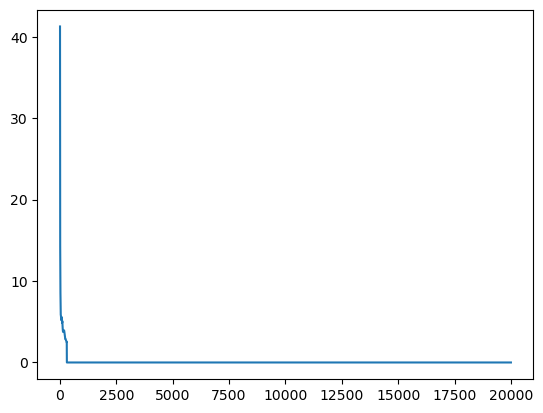

In [56]:
plt.plot(error_log)
plt.show()



In [57]:
Y1 = Y[:,:n_pixels]
Y2 = Y[:,n_pixels:]

image_array = []
for entry in range(0,k):

    snapshot = unvec.transform(Y1[entry,:]+Y2[entry,:])
    image_array += [snapshot]

fig, ax = plt.subplots(k, 1, figsize=(6.4, k * 4.8))
for row in range(0,k):
    ax[row].imshow(image_array[row])
plt.show()